In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

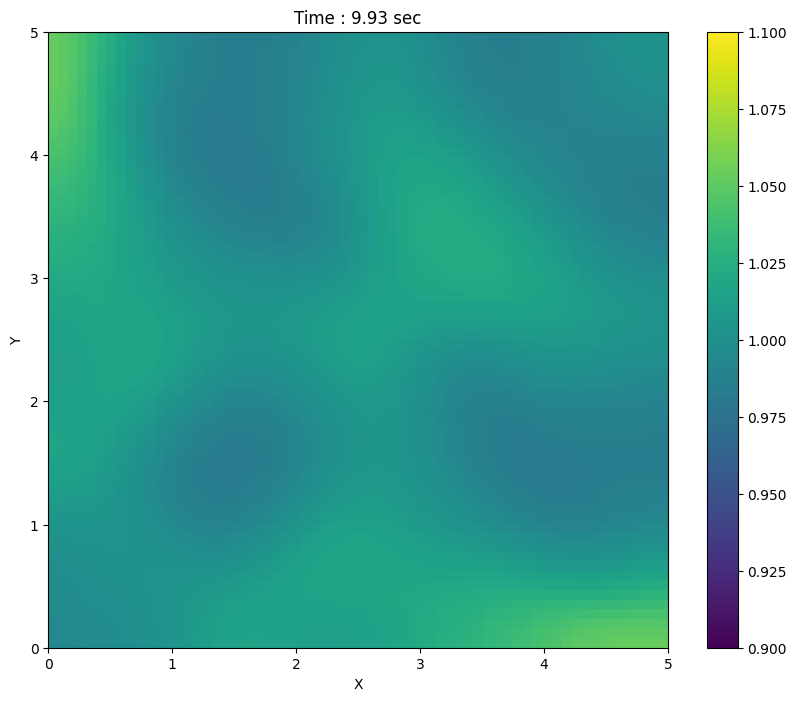

In [93]:
grav = 9.8
Nx, Ny, L = 64, 64, 5.0
dx = L / Nx
dy = L / Ny
x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy
X, Y = np.meshgrid(x, y, indexing='ij')

sx = np.array([1, -1, 1])[:, None]
sy = np.array([1, 1, -1])[:, None]

def f(h, hu, hv):
    u, v = hu / h, hv / h
    f1 = hu
    f2 = h * u ** 2 + 0.5 * grav * h ** 2
    f3 = h * u * v
    return np.array([f1, f2, f3])

def g(h, hu, hv):
    u, v = hu / h, hv / h
    g1 = hv
    g2 = h * u * v
    g3 = h * v ** 2 + 0.5 * grav * h ** 2
    return np.array([g1, g2, g3])

def rusanovX(qL, qR):
    hL, huL, hvL = qL
    hR, huR, hvR = qR
    
    FL, FR = f(hL, huL, hvL), f(hR, huR, hvR)

    uL, uR = huL / hL, huR / hR
    velL, velR = np.abs(uL) + np.sqrt(grav * hL), np.abs(uR) + np.sqrt(grav * hR)
    aX = np.maximum(velL, velR)

    F_X = 0.5 * (FL + FR) - 0.05 * aX * (qR - qL)
    return F_X

def rusanovY(qL, qR):
    hL, huL, hvL = qL
    hR, huR, hvR = qR
        
    GL, GR = g(hL, huL, hvL), g(hR, huR, hvR)

    vL, vR = hvL / hL, hvR / hR
    velL, velR = np.abs(vL) + np.sqrt(grav * hL), np.abs(vR) + np.sqrt(grav * hR)
    aY = np.maximum(velL, velR)

    G_Y = 0.5 * (GL + GR) - 0.05 * aY * (qR - qL)
    return G_Y

def L(q):
    q_ext = np.zeros((3, Nx+2, Ny+2))
    q_ext[:, 1:-1, 1:-1] = q
    
    q_ext[:, 0, 1:-1] = sx * q[:, 0, :]
    q_ext[:, -1, 1:-1] = sx * q[:, -1, :]
    
    q_ext[:, 1:-1, 0] = sy * q[:, :, 0]
    q_ext[:, 1:-1, -1] = sy * q[:, :, -1]
    
    Fx = rusanovX(q_ext[:, :-1, 1:-1], q_ext[:, 1:, 1:-1])
    Fy = rusanovY(q_ext[:, 1:-1, :-1], q_ext[:, 1:-1, 1:])

    return - (Fx[:, 1:, :] - Fx[:, :-1, :]) / dx - (Fy[:, :, 1:] - Fy[:, :, :-1]) / dy
    
def step_ssp_rrk3(q, dt):
    q1 = q + dt * L(q)
    q2 = 0.75 * q + 0.25 * (q1 + dt * L(q1))
    q_next = q / 3 + ( 2 / 3 ) * (q2 + dt * L(q2))
    return q_next

h0 = 1.0 + 3.0*np.exp(-100.0*(X - 1.5)**2 + -100.0*(Y - 1.5)**2)
q = np.array([h0, np.zeros_like(h0), np.zeros_like(h0)])
m0 = q[0].sum() * dx

T = 10.0
t = 0.0
cfl = 0.4
k = 0

E = []

while t < T:
    h, u, v = q[0], q[1] / q[0], q[2] / q[0]
    vel = (np.abs(u) + np.sqrt(grav*h)).max() / dx + (np.abs(v) + np.sqrt(grav*h)).max() / dy
    dt = min(cfl / vel, T - t)
    q = step_ssp_rrk3(q, dt)
    t += dt
    k += 1

    E.append(np.sum(0.5 * h * (u**2 + v**2) + 0.5 * grav * h**2) * dx * dy)
             
    if k % 20 == 0 or False:
        clear_output(wait=True)
        plt.figure(figsize=(10,8))
        #plt.quiver(X[::5, ::5], Y[::5, ::5], u[::5, ::5], v[::5, ::5])
        plt.pcolormesh(X, Y, h)
        plt.colorbar()
        plt.clim(0.9,1.1)
        plt.title(f"Time : {t:.2f} sec")
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.show()
        plt.pause(0.01)

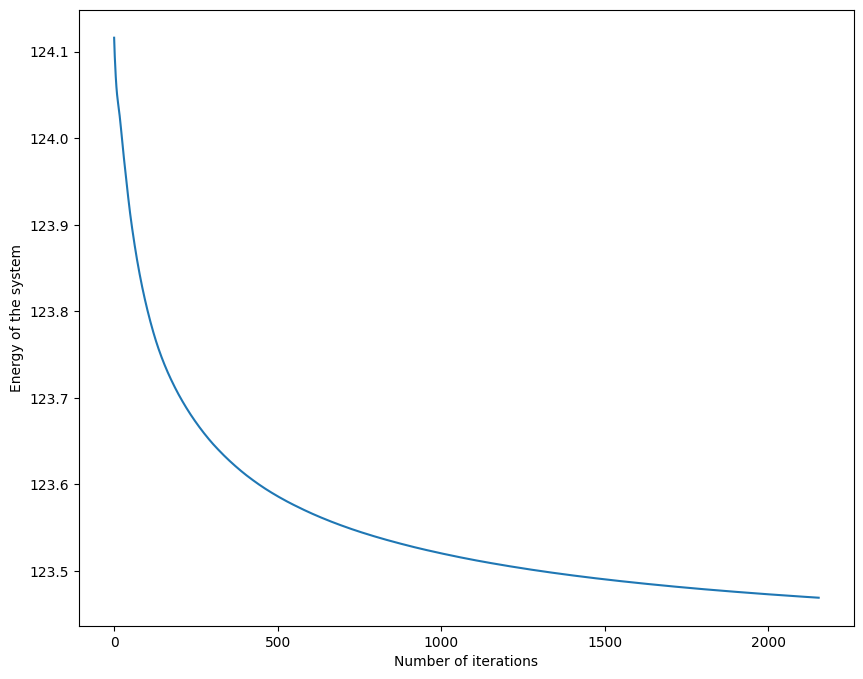

In [96]:
plt.figure(figsize=(10,8))
plt.plot(E)
plt.xlabel("Number of iterations")
plt.ylabel("Energy of the system")
plt.show()